<a href="https://colab.research.google.com/github/walk0504/DeepLearningIndustryAIChallenge/blob/main/Amazon_Review_Sentiment_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q datasets transformers  accelerate scikit-learn

In [ ]:

from datasets import load_dataset

# Load the English Amazon customer reviews
dataset = load_dataset(
    "goosmanlei/amazon_reviews_multi",
    "en"
)

# Check the dataset sizes
print(dataset)

# Display an example review
print("\nExample review:")
print(dataset["train"][0]["review_body"])

print("\nStar rating:")
print(dataset["train"][0]["stars"])


README.md:   0%|          | 0.00/2.62k [00:00<?, ?B/s]

en/train.jsonl.gz: reconstructing file:   0%|          |  0.00B / 21.5MB            

en/train.jsonl.gz: downloading bytes:           |  0.00B            

en/validation.jsonl.gz: reconstructing file:   0%|          |  0.00B /  542kB            

en/validation.jsonl.gz: downloading bytes:           |  0.00B            

en/test.jsonl.gz: reconstructing file:   0%|          |  0.00B /  536kB            

en/test.jsonl.gz: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/200000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category'],
        num_rows: 200000
    })
    validation: Dataset({
        features: ['review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category'],
        num_rows: 5000
    })
    test: Dataset({
        features: ['review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category'],
        num_rows: 5000
    })
})

Example review:
Arrived broken. Manufacturer defect. Two of the legs of the base were not completely formed, so there was no way to insert the casters. I unpackaged the entire chair and hardware before noticing this. So, I'll spend twice the amount of time boxing up the whole useless thing and send it back with a 1-star review of part of a chair I never got to sit in. I will go so far as to include a picture of what t

In [ ]:

import pandas as pd

# Count how many reviews have each star rating
for split in ["train", "validation", "test"]:
    counts = pd.Series(dataset[split]["stars"]).value_counts().sort_index()

    print(f"\n{split.upper()} STAR RATINGS:")
    print(counts)



TRAIN STAR RATINGS:
1    40000
2    40000
3    40000
4    40000
5    40000
Name: count, dtype: int64

VALIDATION STAR RATINGS:
1    1000
2    1000
3    1000
4    1000
5    1000
Name: count, dtype: int64

TEST STAR RATINGS:
1    1000
2    1000
3    1000
4    1000
5    1000
Name: count, dtype: int64


In [ ]:

import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))


GPU available: True
GPU name: Tesla T4


In [ ]:

from datasets import DatasetDict

# Turn star ratings into positive and negative labels
def prepare_review(example):
    example["label"] = 0 if example["stars"] <= 2 else 1
    return example

# Remove neutral (3-star) reviews
binary_dataset = DatasetDict()

for split in ["train", "validation", "test"]:
    reviews = dataset[split].filter(
        lambda example: example["stars"] != 3
    )
    binary_dataset[split] = reviews.map(prepare_review)

# Check the results
for split in binary_dataset:
    reviews = binary_dataset[split]
    negative = reviews["label"].count(0)
    positive = reviews["label"].count(1)

    print(f"{split}: {len(reviews)} reviews")
    print(f"  Negative: {negative}")
    print(f"  Positive: {positive}")


Filter:   0%|          | 0/200000 [00:00<?, ? examples/s]

Map:   0%|          | 0/160000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/5000 [00:00<?, ? examples/s]

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/5000 [00:00<?, ? examples/s]

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

train: 160000 reviews
  Negative: 80000
  Positive: 80000
validation: 4000 reviews
  Negative: 2000
  Positive: 2000
test: 4000 reviews
  Negative: 2000
  Positive: 2000


In [ ]:

# Check for duplicate review text within and across splits
review_sets = {}

for split in ["train", "validation", "test"]:
    texts = [text.strip().lower() for text in binary_dataset[split]["review_body"]]
    unique_texts = set(texts)
    review_sets[split] = unique_texts

    print(f"{split}: {len(texts) - len(unique_texts)} duplicate review texts")

print("\nDuplicates across splits:")
print("Train / Validation:", len(review_sets["train"] & review_sets["validation"]))
print("Train / Test:", len(review_sets["train"] & review_sets["test"]))
print("Validation / Test:", len(review_sets["validation"] & review_sets["test"]))


train: 563 duplicate review texts
validation: 1 duplicate review texts
test: 0 duplicate review texts

Duplicates across splits:
Train / Validation: 19
Train / Test: 18
Validation / Test: 1


In [ ]:

from datasets import DatasetDict

# Create a consistent version of each review for checking duplicates
def add_clean_text(example):
    example["clean_text"] = " ".join(
        example["review_body"].lower().split()
    )
    return example

cleaned = DatasetDict()

for split in ["train", "validation", "test"]:
    cleaned[split] = binary_dataset[split].map(add_clean_text)

# Work from test backward to prevent overlap
seen = set()

for split in ["test", "validation", "train"]:
    original_count = len(cleaned[split])

    # Remove repeated review text and overlaps with protected splits
    keep_indices = []

    for i, text in enumerate(cleaned[split]["clean_text"]):
        if text not in seen:
            keep_indices.append(i)
            seen.add(text)

    cleaned[split] = cleaned[split].select(keep_indices)

    print(
        f"{split}: {original_count} -> {len(cleaned[split])} reviews"
    )

# Check that no review text appears across splits
assert not (
    set(cleaned["train"]["clean_text"])
    & set(cleaned["validation"]["clean_text"])
)

assert not (
    set(cleaned["train"]["clean_text"])
    & set(cleaned["test"]["clean_text"])
)

assert not (
    set(cleaned["validation"]["clean_text"])
    & set(cleaned["test"]["clean_text"])
)

print("\nDuplicate check passed!")


Map:   0%|          | 0/160000 [00:00<?, ? examples/s]

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

test: 4000 -> 4000 reviews
validation: 4000 -> 3998 reviews
train: 160000 -> 159401 reviews

Duplicate check passed!


In [ ]:

# Check class balance after removing duplicates

for split in ["train", "validation", "test"]:
    labels = pd.Series(cleaned[split]["label"])

    print(f"\n{split.upper()}")
    print("Negative reviews:", (labels == 0).sum())
    print("Positive reviews:", (labels == 1).sum())
    print("Total reviews:", len(labels))



TRAIN
Negative reviews: 79759
Positive reviews: 79642
Total reviews: 159401

VALIDATION
Negative reviews: 1999
Positive reviews: 1999
Total reviews: 3998

TEST
Negative reviews: 2000
Positive reviews: 2000
Total reviews: 4000


In [ ]:

from datasets import DatasetDict, concatenate_datasets

# Select an equal number of positive and negative reviews
def balanced_sample(data, total, seed=42):
    negatives = data.filter(lambda x: x["label"] == 0)
    positives = data.filter(lambda x: x["label"] == 1)

    negatives = negatives.shuffle(seed=seed).select(range(total // 2))
    positives = positives.shuffle(seed=seed).select(range(total // 2))

    return concatenate_datasets(
        [negatives, positives]
    ).shuffle(seed=seed)

# Temporary dataset for measuring training speed
speed_test_data = DatasetDict({
    "train": balanced_sample(cleaned["train"], 1000),
    "validation": balanced_sample(cleaned["validation"], 200)
})

print("Speed test training reviews:", len(speed_test_data["train"]))
print("Speed test validation reviews:", len(speed_test_data["validation"]))


Filter:   0%|          | 0/159401 [00:00<?, ? examples/s]

Filter:   0%|          | 0/159401 [00:00<?, ? examples/s]

Filter:   0%|          | 0/3998 [00:00<?, ? examples/s]

Filter:   0%|          | 0/3998 [00:00<?, ? examples/s]

Speed test training reviews: 1000
Speed test validation reviews: 200


In [ ]:

from transformers import AutoTokenizer

# Choose our pre-trained model
model_name = "distilbert-base-uncased"

# Load its tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Convert review text into numbers the model understands
def tokenize_reviews(batch):
    return tokenizer(
        batch["review_body"],
        truncation=True,
        max_length=128
    )

# Prepare our temporary speed-test dataset
tokenized_speed_data = speed_test_data.map(
    tokenize_reviews,
    batched=True
)

print("Tokenization complete!")
print("Training reviews:", len(tokenized_speed_data["train"]))
print("Validation reviews:", len(tokenized_speed_data["validation"]))


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

Tokenization complete!
Training reviews: 1000
Validation reviews: 200


In [ ]:

import time
import torch
from transformers import (
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)

# Load pre-trained DistilBERT for positive/negative reviews
model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
)

# Freeze the original DistilBERT layers
# Only train the classification layers
for param in model.distilbert.parameters():
    param.requires_grad = False

# Automatically pad reviews to the right length
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# Training settings for our speed test
training_args = TrainingArguments(
    output_dir="./speed_test_results",
    num_train_epochs=1,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-4,
    eval_strategy="epoch",
    save_strategy="no",
    logging_steps=20,
    report_to="none",
    seed=42
)

# Set up the trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_speed_data["train"],
    eval_dataset=tokenized_speed_data["validation"],
    data_collator=data_collator,
    processing_class=tokenizer
)

# Measure how long training takes
start_time = time.time()

trainer.train()

elapsed = time.time() - start_time

print(f"\nTraining time: {elapsed:.1f} seconds")
print(f"Training time: {elapsed / 60:.2f} minutes")
print("GPU:", torch.cuda.get_device_name(0))


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss
1,0.592020,0.588657



Training time: 4.9 seconds
Training time: 0.08 minutes
GPU: Tesla T4


In [ ]:

# Create our proposed dataset for the official experiments

experiment_data = DatasetDict({
    "train": balanced_sample(cleaned["train"], 16000),
    "validation": balanced_sample(cleaned["validation"], 2000),
    "test": cleaned["test"]
})

# Display dataset sizes
for split in experiment_data:
    print(f"{split}: {len(experiment_data[split])} reviews")

print("\nExperiment dataset created!")


train: 16000 reviews
validation: 2000 reviews
test: 4000 reviews

Experiment dataset created!


In [ ]:

# Convert our experiment reviews into tokens
tokenized_experiment_data = experiment_data.map(
    tokenize_reviews,
    batched=True
)

# Check that everything worked
for split in tokenized_experiment_data:
    print(f"{split}: {len(tokenized_experiment_data[split])} reviews")

print("\nTokenization complete!")


Map:   0%|          | 0/16000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

train: 16000 reviews
validation: 2000 reviews
test: 4000 reviews

Tokenization complete!


In [14]:

from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score
import numpy as np

# Get the actual labels from our validation dataset
actual = np.array(experiment_data["validation"]["label"])

# Simple benchmark: predict every review is negative (0)
predicted = np.zeros(len(actual), dtype=int)

# Calculate benchmark results
print("MAJORITY-CLASS BENCHMARK (NEGATIVE PREDICTION)")
print("Accuracy:", round(accuracy_score(actual, predicted), 4))
print("F1-score (negative):", round(f1_score(actual, predicted, pos_label=0), 4))
print("Recall (negative):", round(recall_score(actual, predicted, pos_label=0), 4))
print("Precision (negative):", round(precision_score(actual, predicted, pos_label=0), 4))


MAJORITY-CLASS BENCHMARK (NEGATIVE PREDICTION)
Accuracy: 0.5
F1-score (negative): 0.6667
Recall (negative): 1.0
Precision (negative): 0.5


In [15]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import numpy as np

# Calculate the same measurements for every model
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "negative_precision": precision_score(
            labels, predictions, pos_label=0, zero_division=0
        ),
        "negative_recall": recall_score(
            labels, predictions, pos_label=0, zero_division=0
        ),
        "negative_f1": f1_score(
            labels, predictions, pos_label=0, zero_division=0
        )
    }

print("Evaluation metrics are ready!")


Evaluation metrics are ready!


In [16]:

import time
import torch
from transformers import (
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    set_seed
)

# Make our results easier to reproduce
set_seed(42)

# Load a fresh pre-trained DistilBERT model
baseline_model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
)

# Freeze the original DistilBERT layers
for param in baseline_model.distilbert.parameters():
    param.requires_grad = False

# Set up our training settings
baseline_args = TrainingArguments(
    output_dir="./baseline_results",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-4,
    eval_strategy="epoch",
    save_strategy="no",
    logging_strategy="epoch",
    report_to="none",
    seed=42,
    data_seed=42
)

# Prepare variable-length reviews
data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

# Create our baseline trainer
baseline_trainer = Trainer(
    model=baseline_model,
    args=baseline_args,
    train_dataset=tokenized_experiment_data["train"],
    eval_dataset=tokenized_experiment_data["validation"],
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)

# Train and measure time
start_time = time.time()

baseline_trainer.train()

baseline_time = time.time() - start_time

# Evaluate on validation data only
baseline_results = baseline_trainer.evaluate()

print("\nBASELINE RESULTS")
print("Accuracy:", round(baseline_results["eval_accuracy"], 4))
print("Negative precision:", round(baseline_results["eval_negative_precision"], 4))
print("Negative recall:", round(baseline_results["eval_negative_recall"], 4))
print("Negative F1:", round(baseline_results["eval_negative_f1"], 4))
print("Training time (minutes):", round(baseline_time / 60, 2))


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Negative Precision,Negative Recall,Negative F1
1,0.373909,0.325614,0.851000,0.855263,0.845000,0.850101
2,0.328126,0.329131,0.857000,0.817616,0.919000,0.865348
3,0.315966,0.321704,0.856000,0.846304,0.870000,0.857988


Training Loss,Validation Loss,Epoch,Accuracy,Negative Precision,Negative Recall,Negative F1
0.315966,0.321704,3,0.856000,0.846304,0.870000,0.857988



BASELINE RESULTS
Accuracy: 0.856
Negative precision: 0.8463
Negative recall: 0.87
Negative F1: 0.858
Training time (minutes): 3.27


In [17]:

import pandas as pd

# Record results from our official baseline
experiment_log = pd.DataFrame([{
    "Run": "Baseline",
    "Change": "Frozen DistilBERT, 3 epochs",
    "Learning Rate": 0.0002,
    "Negative F1": baseline_results["eval_negative_f1"],
    "Negative Recall": baseline_results["eval_negative_recall"],
    "Negative Precision": baseline_results["eval_negative_precision"],
    "Accuracy": baseline_results["eval_accuracy"],
    "Training Minutes": baseline_time / 60
}])

display(experiment_log)


,Run,Change,Learning Rate,Negative F1,Negative Recall,Negative Precision,Accuracy,Training Minutes
0,Baseline,"Frozen DistilBERT, 3 epochs",0.0002,0.857988,0.87,0.846304,0.856,3.265633


In [18]:

# EXPERIMENT 1: Unfreeze the last two DistilBERT layers

set_seed(42)

# Load a fresh model so the experiment starts fairly
exp1_model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
)

# First freeze all original DistilBERT layers
for param in exp1_model.distilbert.parameters():
    param.requires_grad = False

# Unfreeze only the last two transformer layers
for layer in exp1_model.distilbert.transformer.layer[-2:]:
    for param in layer.parameters():
        param.requires_grad = True

# Use the same settings as our baseline
exp1_args = TrainingArguments(
    output_dir="./experiment1_results",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-4,
    eval_strategy="epoch",
    save_strategy="no",
    logging_strategy="epoch",
    report_to="none",
    seed=42,
    data_seed=42
)

# Create the trainer
exp1_trainer = Trainer(
    model=exp1_model,
    args=exp1_args,
    train_dataset=tokenized_experiment_data["train"],
    eval_dataset=tokenized_experiment_data["validation"],
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)

# Train and measure runtime
start_time = time.time()

exp1_trainer.train()

exp1_time = time.time() - start_time

# Evaluate on validation data only
exp1_results = exp1_trainer.evaluate()

print("\nEXPERIMENT 1 RESULTS")
print("Accuracy:", round(exp1_results["eval_accuracy"], 4))
print("Negative precision:", round(exp1_results["eval_negative_precision"], 4))
print("Negative recall:", round(exp1_results["eval_negative_recall"], 4))
print("Negative F1:", round(exp1_results["eval_negative_f1"], 4))
print("Training time (minutes):", round(exp1_time / 60, 2))


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Negative Precision,Negative Recall,Negative F1
1,0.298670,0.306068,0.892000,0.912632,0.867000,0.889231
2,0.211341,0.312155,0.895500,0.862511,0.941000,0.900048
3,0.147781,0.322716,0.900500,0.894581,0.908000,0.901241


Training Loss,Validation Loss,Epoch,Accuracy,Negative Precision,Negative Recall,Negative F1
0.147781,0.322716,3,0.900500,0.894581,0.908000,0.901241



EXPERIMENT 1 RESULTS
Accuracy: 0.9005
Negative precision: 0.8946
Negative recall: 0.908
Negative F1: 0.9012
Training time (minutes): 4.61


In [19]:

# Record Experiment 1 results

experiment_log.loc[len(experiment_log)] = {
    "Run": "Experiment 1",
    "Change": "Unfroze last 2 DistilBERT layers",
    "Learning Rate": 0.0002,
    "Negative F1": exp1_results["eval_negative_f1"],
    "Negative Recall": exp1_results["eval_negative_recall"],
    "Negative Precision": exp1_results["eval_negative_precision"],
    "Accuracy": exp1_results["eval_accuracy"],
    "Training Minutes": exp1_time / 60
}

display(experiment_log)


,Run,Change,Learning Rate,Negative F1,Negative Recall,Negative Precision,Accuracy,Training Minutes
0,Baseline,"Frozen DistilBERT, 3 epochs",0.0002,0.857988,0.870,0.846304,0.8560,3.265633
1,Experiment 1,Unfroze last 2 DistilBERT layers,0.0002,0.901241,0.908,0.894581,0.9005,4.612671


In [20]:

# EXPERIMENT 2: Lower learning rate

set_seed(42)

# Load a fresh pre-trained DistilBERT model
exp2_model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
)

# Keep all original DistilBERT layers frozen
for param in exp2_model.distilbert.parameters():
    param.requires_grad = False

# Same baseline settings, except for learning rate
exp2_args = TrainingArguments(
    output_dir="./experiment2_results",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=5e-5,
    eval_strategy="epoch",
    save_strategy="no",
    logging_strategy="epoch",
    report_to="none",
    seed=42,
    data_seed=42
)

# Set up the trainer
exp2_trainer = Trainer(
    model=exp2_model,
    args=exp2_args,
    train_dataset=tokenized_experiment_data["train"],
    eval_dataset=tokenized_experiment_data["validation"],
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)

# Train and measure time
start_time = time.time()

exp2_trainer.train()

exp2_time = time.time() - start_time

# Evaluate using validation data only
exp2_results = exp2_trainer.evaluate()

print("\nEXPERIMENT 2 RESULTS")
print("Accuracy:", round(exp2_results["eval_accuracy"], 4))
print("Negative precision:", round(exp2_results["eval_negative_precision"], 4))
print("Negative recall:", round(exp2_results["eval_negative_recall"], 4))
print("Negative F1:", round(exp2_results["eval_negative_f1"], 4))
print("Training time (minutes):", round(exp2_time / 60, 2))


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Negative Precision,Negative Recall,Negative F1
1,0.440441,0.348530,0.845000,0.837573,0.856000,0.846686
2,0.342898,0.334103,0.852500,0.843233,0.866000,0.854465
3,0.332574,0.333175,0.853000,0.846078,0.863000,0.854455


Training Loss,Validation Loss,Epoch,Accuracy,Negative Precision,Negative Recall,Negative F1
0.332574,0.333175,3,0.853000,0.846078,0.863000,0.854455



EXPERIMENT 2 RESULTS
Accuracy: 0.853
Negative precision: 0.8461
Negative recall: 0.863
Negative F1: 0.8545
Training time (minutes): 3.21


In [21]:

# Record Experiment 2 results

experiment_log.loc[len(experiment_log)] = {
    "Run": "Experiment 2",
    "Change": "Lowered learning rate to 0.00005",
    "Learning Rate": 0.00005,
    "Negative F1": exp2_results["eval_negative_f1"],
    "Negative Recall": exp2_results["eval_negative_recall"],
    "Negative Precision": exp2_results["eval_negative_precision"],
    "Accuracy": exp2_results["eval_accuracy"],
    "Training Minutes": exp2_time / 60
}

display(experiment_log)


,Run,Change,Learning Rate,Negative F1,Negative Recall,Negative Precision,Accuracy,Training Minutes
0,Baseline,"Frozen DistilBERT, 3 epochs",0.00020,0.857988,0.870,0.846304,0.8560,3.265633
1,Experiment 1,Unfroze last 2 DistilBERT layers,0.00020,0.901241,0.908,0.894581,0.9005,4.612671
2,Experiment 2,Lowered learning rate to 0.00005,0.00005,0.854455,0.863,0.846078,0.8530,3.207991


In [22]:

# EXPERIMENT 3: Increase review length to 256 tokens

set_seed(42)

# Tokenize the same reviews with a longer limit
def tokenize_longer_reviews(batch):
    return tokenizer(
        batch["review_body"],
        truncation=True,
        max_length=256
    )

longer_tokenized_data = experiment_data.map(
    tokenize_longer_reviews,
    batched=True
)

# Load a fresh DistilBERT model
exp3_model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
)

# Freeze original DistilBERT layers (same as baseline)
for param in exp3_model.distilbert.parameters():
    param.requires_grad = False

# Same settings as baseline, only review length changes
exp3_args = TrainingArguments(
    output_dir="./experiment3_results",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-4,
    eval_strategy="epoch",
    save_strategy="no",
    logging_strategy="epoch",
    report_to="none",
    seed=42,
    data_seed=42
)

# Create trainer
exp3_trainer = Trainer(
    model=exp3_model,
    args=exp3_args,
    train_dataset=longer_tokenized_data["train"],
    eval_dataset=longer_tokenized_data["validation"],
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)

# Train and measure time
start_time = time.time()

exp3_trainer.train()

exp3_time = time.time() - start_time

# Evaluate on validation data only
exp3_results = exp3_trainer.evaluate()

print("\nEXPERIMENT 3 RESULTS")
print("Accuracy:", round(exp3_results["eval_accuracy"], 4))
print("Negative precision:", round(exp3_results["eval_negative_precision"], 4))
print("Negative recall:", round(exp3_results["eval_negative_recall"], 4))
print("Negative F1:", round(exp3_results["eval_negative_f1"], 4))
print("Training time (minutes):", round(exp3_time / 60, 2))


Map:   0%|          | 0/16000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Negative Precision,Negative Recall,Negative F1
1,0.372012,0.323261,0.856000,0.865503,0.843000,0.854103
2,0.330066,0.318179,0.862500,0.839102,0.897000,0.867086
3,0.315991,0.315571,0.861500,0.852683,0.874000,0.863210


Training Loss,Validation Loss,Epoch,Accuracy,Negative Precision,Negative Recall,Negative F1
0.315991,0.315571,3,0.861500,0.852683,0.874000,0.863210



EXPERIMENT 3 RESULTS
Accuracy: 0.8615
Negative precision: 0.8527
Negative recall: 0.874
Negative F1: 0.8632
Training time (minutes): 3.78


In [23]:

# Record Experiment 3 results

experiment_log.loc[len(experiment_log)] = {
    "Run": "Experiment 3",
    "Change": "Increased maximum tokens to 256",
    "Learning Rate": 0.0002,
    "Negative F1": exp3_results["eval_negative_f1"],
    "Negative Recall": exp3_results["eval_negative_recall"],
    "Negative Precision": exp3_results["eval_negative_precision"],
    "Accuracy": exp3_results["eval_accuracy"],
    "Training Minutes": exp3_time / 60
}

display(experiment_log)


,Run,Change,Learning Rate,Negative F1,Negative Recall,Negative Precision,Accuracy,Training Minutes
0,Baseline,"Frozen DistilBERT, 3 epochs",0.00020,0.857988,0.870,0.846304,0.8560,3.265633
1,Experiment 1,Unfroze last 2 DistilBERT layers,0.00020,0.901241,0.908,0.894581,0.9005,4.612671
2,Experiment 2,Lowered learning rate to 0.00005,0.00005,0.854455,0.863,0.846078,0.8530,3.207991
3,Experiment 3,Increased maximum tokens to 256,0.00020,0.863210,0.874,0.852683,0.8615,3.782310


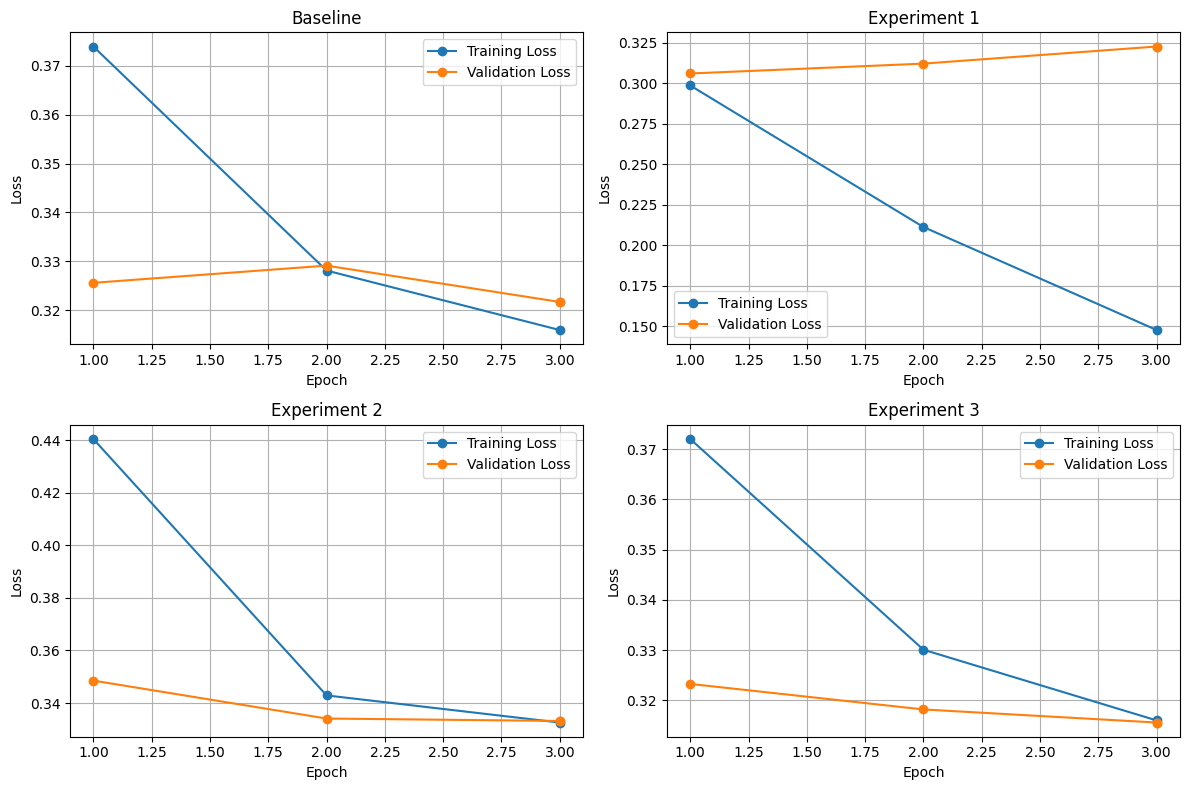

In [25]:

import matplotlib.pyplot as plt

# Collect training and validation loss from each run
trainers = {
    "Baseline": baseline_trainer,
    "Experiment 1": exp1_trainer,
    "Experiment 2": exp2_trainer,
    "Experiment 3": exp3_trainer
}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (name, trainer) in zip(axes.flat, trainers.items()):
    history = trainer.state.log_history

    train_epochs = [
        entry["epoch"] for entry in history
        if "loss" in entry
    ]
    train_losses = [
        entry["loss"] for entry in history
        if "loss" in entry
    ]

    val_epochs = [
        entry["epoch"] for entry in history
        if "eval_loss" in entry
    ]
    val_losses = [
        entry["eval_loss"] for entry in history
        if "eval_loss" in entry
    ]

    ax.plot(train_epochs, train_losses, marker="o", label="Training Loss")
    ax.plot(val_epochs, val_losses, marker="o", label="Validation Loss")

    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(True)


plt.tight_layout()
plt.savefig("training_validation_curves.png", dpi=300, bbox_inches="tight")
plt.show()


In [26]:

import numpy as np
import pandas as pd

# Get Experiment 1 predictions on validation reviews
predictions_output = exp1_trainer.predict(
    tokenized_experiment_data["validation"]
)

# Convert model scores into positive or negative predictions
predicted_labels = np.argmax(
    predictions_output.predictions,
    axis=1
)

# Get the correct labels
actual_labels = np.array(
    experiment_data["validation"]["label"]
)

# Find reviews the model classified incorrectly
wrong_indices = np.where(
    predicted_labels != actual_labels
)[0]

print("Total incorrect predictions:", len(wrong_indices))
print("Total validation reviews:", len(actual_labels))

# Separate the two kinds of mistakes
missed_negative = wrong_indices[
    actual_labels[wrong_indices] == 0
]

false_alarms = wrong_indices[
    actual_labels[wrong_indices] == 1
]

print("Negative reviews missed:", len(missed_negative))
print("Positive reviews incorrectly flagged:", len(false_alarms))


Total incorrect predictions: 199
Total validation reviews: 2000
Negative reviews missed: 92
Positive reviews incorrectly flagged: 107


In [27]:

# Show three missed negative reviews
print("THREE MISSED NEGATIVE REVIEWS\n")

for i, index in enumerate(missed_negative[:3], start=1):
    review = experiment_data["validation"][int(index)]

    print(f"EXAMPLE {i}")
    print("Actual rating:", review["stars"], "stars")
    print("Actual label: Negative")
    print("Model prediction: Positive")
    print("Review text:", review["review_body"])
    print("-" * 60)


THREE MISSED NEGATIVE REVIEWS

EXAMPLE 1
Actual rating: 2 stars
Actual label: Negative
Model prediction: Positive
Review text: I like the color. It has a strange odor to it. It's a little rough.
------------------------------------------------------------
EXAMPLE 2
Actual rating: 2 stars
Actual label: Negative
Model prediction: Positive
Review text: I bought Pink Green and Grey Duct Tape as labels for Moving Boxes. The Grey is just like my regular Duct Tape. If you are going for it because of color, then this isnt it. But the other colors are great!
------------------------------------------------------------
EXAMPLE 3
Actual rating: 2 stars
Actual label: Negative
Model prediction: Positive
Review text: This still doesn’t work well on my computer but I will continue to work on it.
------------------------------------------------------------


In [28]:

import torch

# Convert model scores into probabilities
probabilities = torch.softmax(
    torch.tensor(predictions_output.predictions),
    dim=1
).numpy()

# Examine our three missed negative reviews
for i, index in enumerate(missed_negative[:3], start=1):
    review = experiment_data["validation"][int(index)]

    print(f"\nEXAMPLE {i}")
    print("Actual rating:", review["stars"], "stars")
    print("Actual label: Negative")
    print("Predicted label: Positive")
    print("Positive probability:",
          round(float(probabilities[index][1]) * 100, 2), "%")
    print("Full review:", review["review_body"])
    print("-" * 70)



EXAMPLE 1
Actual rating: 2 stars
Actual label: Negative
Predicted label: Positive
Positive probability: 97.04 %
Full review: I like the color. It has a strange odor to it. It's a little rough.
----------------------------------------------------------------------

EXAMPLE 2
Actual rating: 2 stars
Actual label: Negative
Predicted label: Positive
Positive probability: 90.21 %
Full review: I bought Pink Green and Grey Duct Tape as labels for Moving Boxes. The Grey is just like my regular Duct Tape. If you are going for it because of color, then this isnt it. But the other colors are great!
----------------------------------------------------------------------

EXAMPLE 3
Actual rating: 2 stars
Actual label: Negative
Predicted label: Positive
Positive probability: 91.44 %
Full review: This still doesn’t work well on my computer but I will continue to work on it.
----------------------------------------------------------------------


In [29]:

# Examine three positive reviews incorrectly labeled negative

for i, index in enumerate(false_alarms[:3], start=1):
    review = experiment_data["validation"][int(index)]

    print(f"\nFALSE ALARM {i}")
    print("Actual rating:", review["stars"], "stars")
    print("Actual label: Positive")
    print("Predicted label: Negative")
    print("Negative probability:",
          round(float(probabilities[index][0]) * 100, 2), "%")
    print("Review:", review["review_body"])
    print("-" * 70)



FALSE ALARM 1
Actual rating: 4 stars
Actual label: Positive
Predicted label: Negative
Negative probability: 95.29 %
Review: Get the disk or wait for Netflix, Amazon Prime Video is the worst.
----------------------------------------------------------------------

FALSE ALARM 2
Actual rating: 5 stars
Actual label: Positive
Predicted label: Negative
Negative probability: 98.26 %
Review: If you need centering rings for your wheels and the size you need is made by this brand, stop reading this and just go order them. I'm on my 2nd set (2nd car) and in both cases plastic rings were tried first and always caused wheel wobble at various speeds. Dropped these aluminum rings on and all wheel wobble is gone.
----------------------------------------------------------------------

FALSE ALARM 3
Actual rating: 4 stars
Actual label: Positive
Predicted label: Negative
Negative probability: 90.45 %
Review: Chemical reaction is spot on but the applicator is cardboard so wear gloves as it tends to leak 

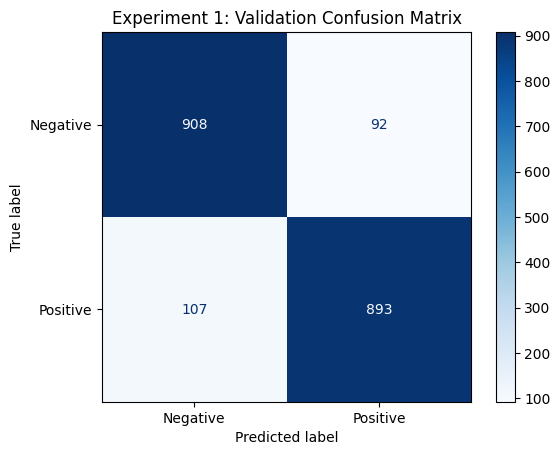

In [30]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Create confusion matrix using validation predictions
cm = confusion_matrix(
    actual_labels,
    predicted_labels,
    labels=[0, 1]
)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Experiment 1: Validation Confusion Matrix")
plt.savefig(
    "validation_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [31]:

# Save the selected Experiment 1 model and tokenizer

import os

model_folder = "./selected_model"
os.makedirs(model_folder, exist_ok=True)

exp1_trainer.save_model(model_folder)
tokenizer.save_pretrained(model_folder)

print("Selected model saved successfully!")
print("Files:", os.listdir(model_folder))


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Selected model saved successfully!
Files: ['model.safetensors', 'config.json', 'tokenizer_config.json', 'tokenizer.json', 'training_args.bin']


In [32]:

# FINAL TEST: Evaluate selected Experiment 1 model

# Run the selected model on the untouched test dataset
final_test_results = exp1_trainer.evaluate(
    eval_dataset=tokenized_experiment_data["test"]
)

print("\nFINAL TEST RESULTS")
print("Accuracy:", round(final_test_results["eval_accuracy"], 4))
print("Negative precision:", round(final_test_results["eval_negative_precision"], 4))
print("Negative recall:", round(final_test_results["eval_negative_recall"], 4))
print("Negative F1:", round(final_test_results["eval_negative_f1"], 4))


Training Loss,Validation Loss,Epoch,Accuracy,Negative Precision,Negative Recall,Negative F1
0.147781,0.262284,3,0.915750,0.900723,0.934500,0.917301



FINAL TEST RESULTS
Accuracy: 0.9157
Negative precision: 0.9007
Negative recall: 0.9345
Negative F1: 0.9173


In [33]:

# Record final test results for our report

final_summary = pd.DataFrame([{
    "Selected Model": "Experiment 1 - Last 2 layers unfrozen",
    "Test Reviews": len(experiment_data["test"]),
    "Accuracy": final_test_results["eval_accuracy"],
    "Negative Precision": final_test_results["eval_negative_precision"],
    "Negative Recall": final_test_results["eval_negative_recall"],
    "Negative F1": final_test_results["eval_negative_f1"]
}])

display(final_summary)


,Selected Model,Test Reviews,Accuracy,Negative Precision,Negative Recall,Negative F1
0,Experiment 1 - Last 2 layers unfrozen,4000,0.91575,0.900723,0.9345,0.917301


In [34]:

import time
import torch
import numpy as np

# Select 100 validation reviews for the speed test
sample_reviews = experiment_data["validation"]["review_body"][:100]

# Use our selected trained model
model = exp1_trainer.model
model.eval()

# Determine which device the model is using
device = next(model.parameters()).device

# Tokenize the reviews using our selected 128-token limit
inputs = tokenizer(
    sample_reviews,
    padding=True,
    truncation=True,
    max_length=128,
    return_tensors="pt"
).to(device)

# Warm up the GPU before measuring
with torch.no_grad():
    _ = model(**inputs)

if device.type == "cuda":
    torch.cuda.synchronize()

# Measure prediction time
start_time = time.perf_counter()

with torch.no_grad():
    outputs = model(**inputs)
    predictions = torch.argmax(outputs.logits, dim=1)

if device.type == "cuda":
    torch.cuda.synchronize()

elapsed = time.perf_counter() - start_time

print("Reviews processed:", len(sample_reviews))
print("Total prediction time:", round(elapsed, 4), "seconds")
print("Average time per review:", round(elapsed / 100, 4), "seconds")
print("Device:", device)


Reviews processed: 100
Total prediction time: 0.304 seconds
Average time per review: 0.003 seconds
Device: cuda:0


In [35]:

# Record prediction-speed results

inference_summary = pd.DataFrame([{
    "Model": "Experiment 1",
    "Hardware": torch.cuda.get_device_name(0),
    "Reviews Processed": len(sample_reviews),
    "Total Inference Seconds": elapsed,
    "Seconds Per Review": elapsed / len(sample_reviews),
    "Includes Tokenization": False
}])

display(inference_summary)


,Model,Hardware,Reviews Processed,Total Inference Seconds,Seconds Per Review,Includes Tokenization
0,Experiment 1,Tesla T4,100,0.304047,0.00304,False


In [36]:

import shutil
from google.colab import files

# Compress the trained model and tokenizer into one ZIP file
shutil.make_archive(
    "Amazon_Review_Selected_Model",
    "zip",
    root_dir=".",
    base_dir="selected_model"
)

# Download the ZIP to your computer
files.download("Amazon_Review_Selected_Model.zip")

print("Model backup created!")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Model backup created!


In [37]:

import os
import zipfile
from google.colab import files

# Save our experiment results as CSV files
experiment_log.to_csv("experiment_comparison.csv", index=False)
final_summary.to_csv("final_test_results.csv", index=False)
inference_summary.to_csv("inference_speed_results.csv", index=False)

# Files we want to preserve
evidence_files = [
    "experiment_comparison.csv",
    "final_test_results.csv",
    "inference_speed_results.csv",
    "training_validation_curves.png",
    "validation_confusion_matrix.png"
]

# Create a ZIP containing our results and graphs
with zipfile.ZipFile("Amazon_Review_Project_Evidence.zip", "w") as zip_file:
    for filename in evidence_files:
        if os.path.exists(filename):
            zip_file.write(filename)
            print("Added:", filename)
        else:
            print("Missing:", filename)

# Download the evidence
files.download("Amazon_Review_Project_Evidence.zip")

print("\nEvidence backup created!")


Added: experiment_comparison.csv
Added: final_test_results.csv
Added: inference_speed_results.csv
Added: training_validation_curves.png
Added: validation_confusion_matrix.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Evidence backup created!
